# ⚡ PowerCast: Household Electricity Forecasting
**Team:** Rana · Salwa · Renad · Raneem

**Le Wagon Data Science #2344 · Project Weeks**

---

**Problem:**
We want to forecast a household's hourly electricity consumption for the next 24 hours using data available up to that time.

| Decision | Choice |
|---|---|
| Target | `Global_active_power` (kW) |
| Time step | 1 hour |
| Horizon | Next 24 hours |
| Main metric | MAE (kW) |
| Extra metrics | RMSE · sMAPE · R² |

**Contents:**
1. Setup
2. Data Preparation
3. Key Findings (EDA)
4. Models: Baseline vs LSTM
5. Results & Error Analysis
6. Final Test Evaluation
7. Forecast Demo
8. Limitations & Conclusion

## 1. Setup

In [22]:
from google.colab import drive
drive.mount('/content/drive')

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE = '/content/drive/MyDrive/PowerCast'
SEED = 42
np.random.seed(SEED)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Data Preparation

Raw data: **2,075,259 minute readings** (2006-12-16 → 2010-11-26), from the UCI Household Power Consumption dataset.

**Main steps** (full details in `01_data_cleaning_rana.ipynb`):
1. Combined `Date` + `Time` into one datetime index, sorted, no duplicates.
2. Resampled minutes → **hourly averages** (34,589 hours).
3. Filled 421 missing hours (1.2%):
   - short gaps (≤ 3h) → time interpolation
   - long gaps (14–119h) → same hour from the previous week (past data only)
4. Split **by date** (no shuffle): Train → 2009-12-31 · Validation 2010-01 to 2010-06 · Test 2010-07 → end.

In [23]:
df = pd.read_csv(f'{BASE}/data/hourly_clean.csv', index_col=0, parse_dates=True)

with open(f'{BASE}/data/split_dates.json') as f:
    splits = json.load(f)

print(df.shape)
print(df['split'].value_counts())
df.head()

(34589, 9)
split
train    26671
val       4344
test      3574
Name: count, dtype: int64


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,was_missing,split
datetime,,,,,,,,,
2006-12-16 17:00:00,4.222889,0.229000,234.643889,18.100000,0.0,0.527778,16.861111,0,train
2006-12-16 18:00:00,3.632200,0.080033,234.580167,15.600000,0.0,6.716667,16.866667,0,train
2006-12-16 19:00:00,3.400233,0.085233,233.232500,14.503333,0.0,1.433333,16.683333,0,train
2006-12-16 20:00:00,3.268567,0.075100,234.071500,13.916667,0.0,0.000000,16.783333,0,train
2006-12-16 21:00:00,3.056467,0.076667,237.158667,13.046667,0.0,0.416667,17.216667,0,train


## 3. Key Findings (EDA)

Full analysis in `02_EDA_salwa.ipynb` (train data only).

- **Daily pattern:** lowest at 03:00 (0.44 kW), highest at 20:00 (1.95 kW).
- **Weekly pattern:** weekends are 22% higher than weekdays (1.26 vs 1.03 kW).
- **Yearly seasonality:** winter is higher (Jan 1.47 kW) than summer (Aug 0.57 kW).
- **Repetition:** autocorrelation peaks at 24h (0.43) and 168h (0.47), so past days and weeks help the forecast.

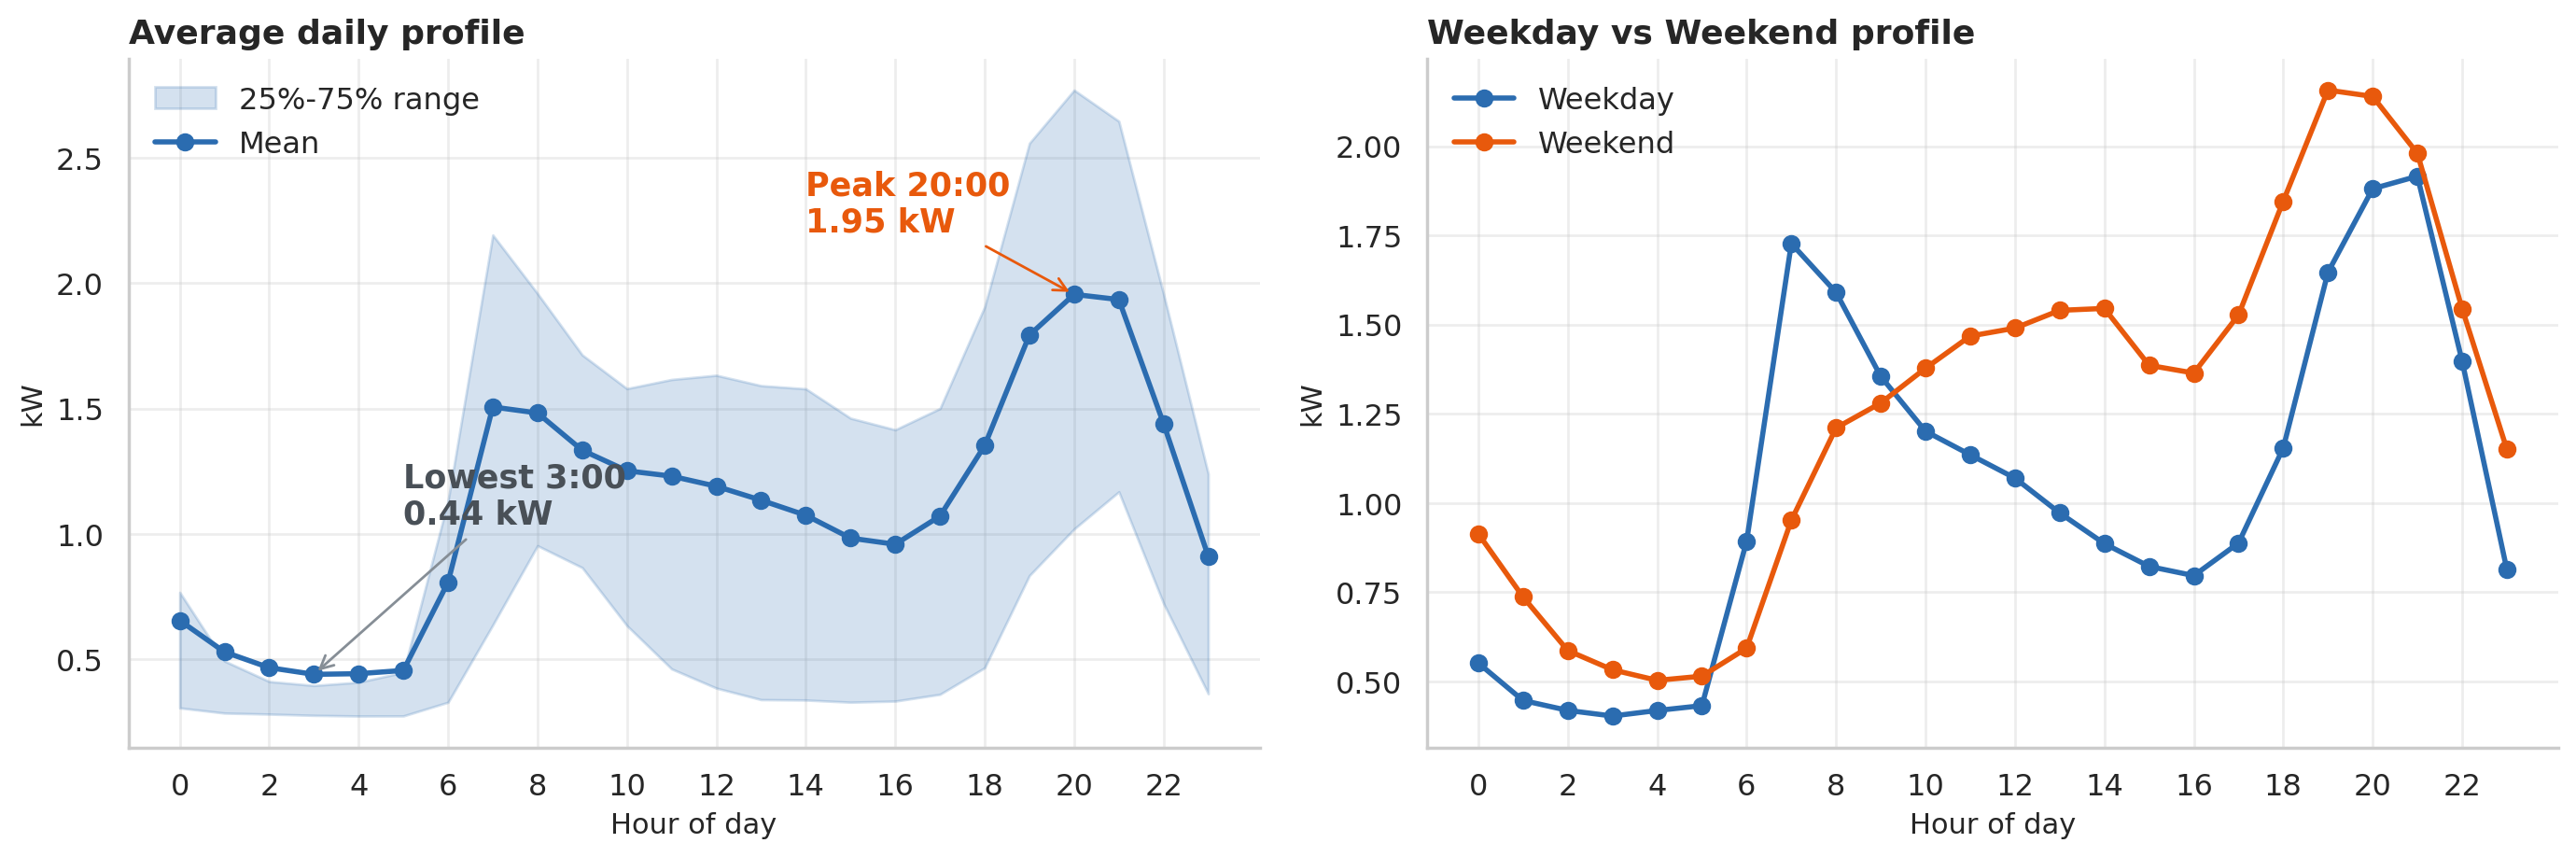

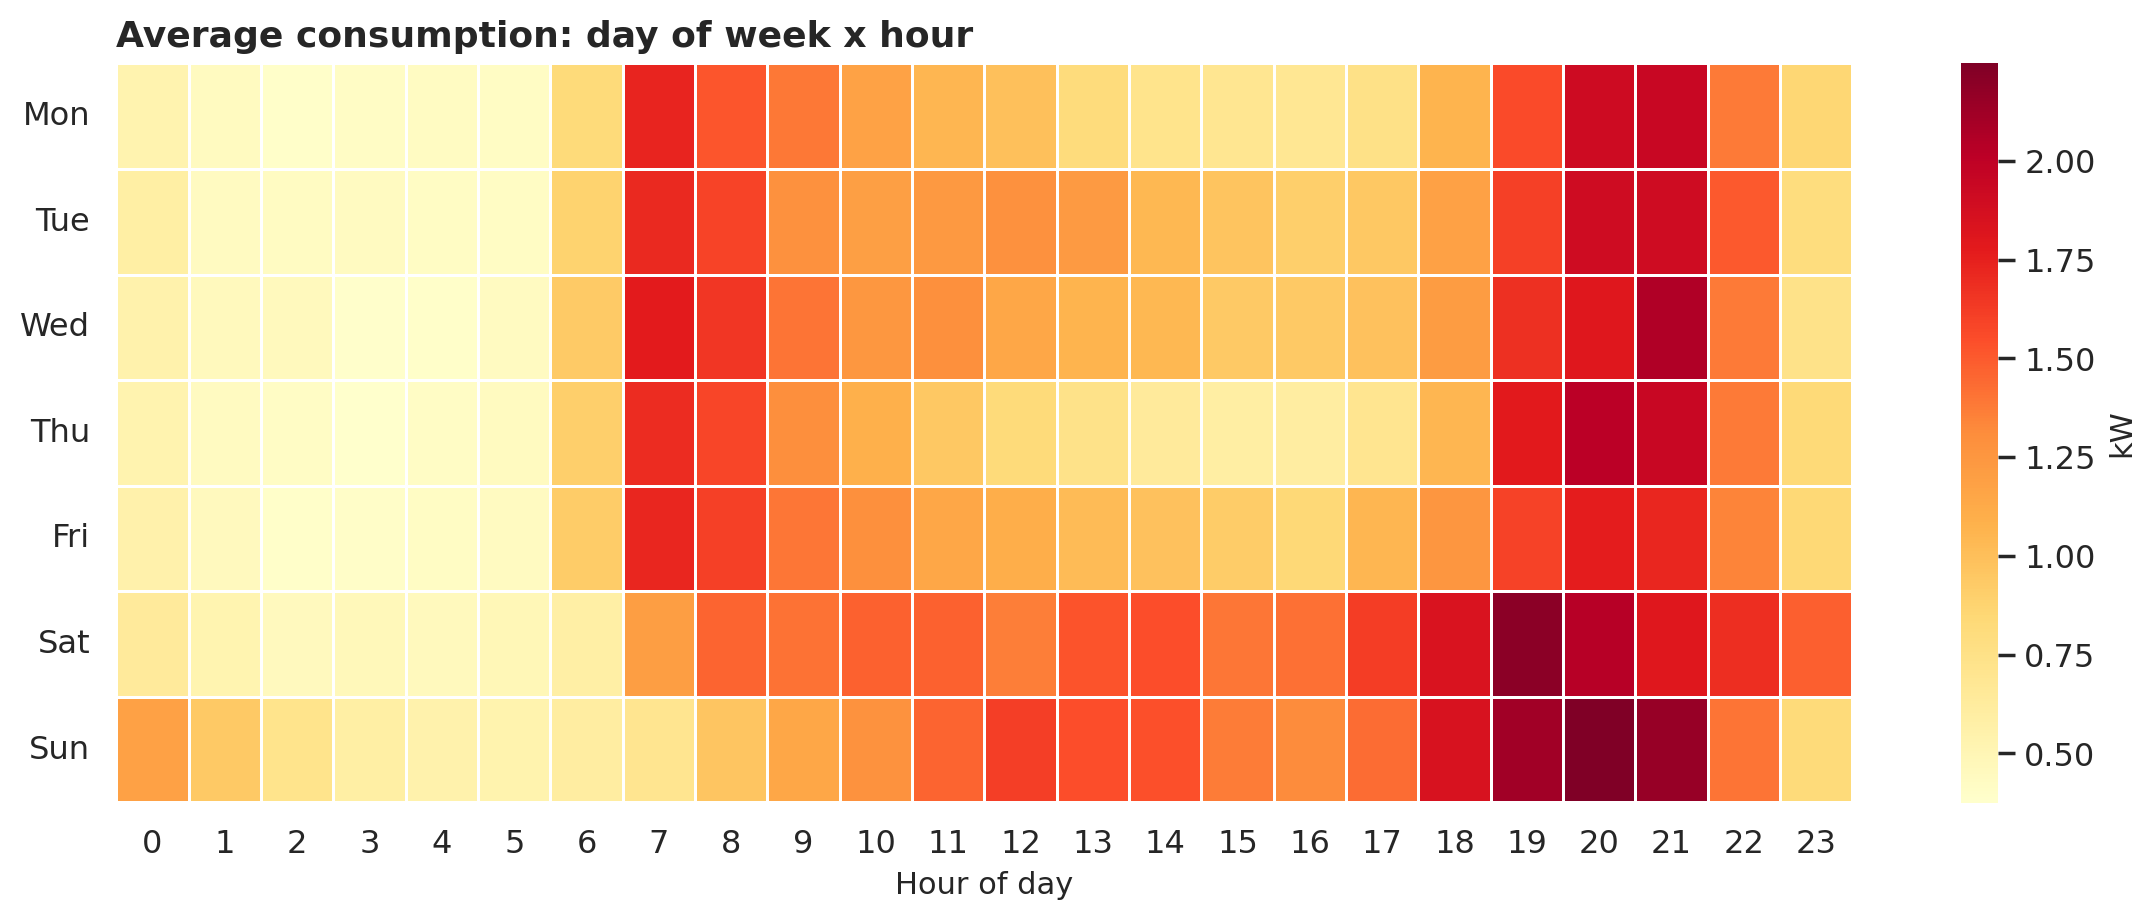

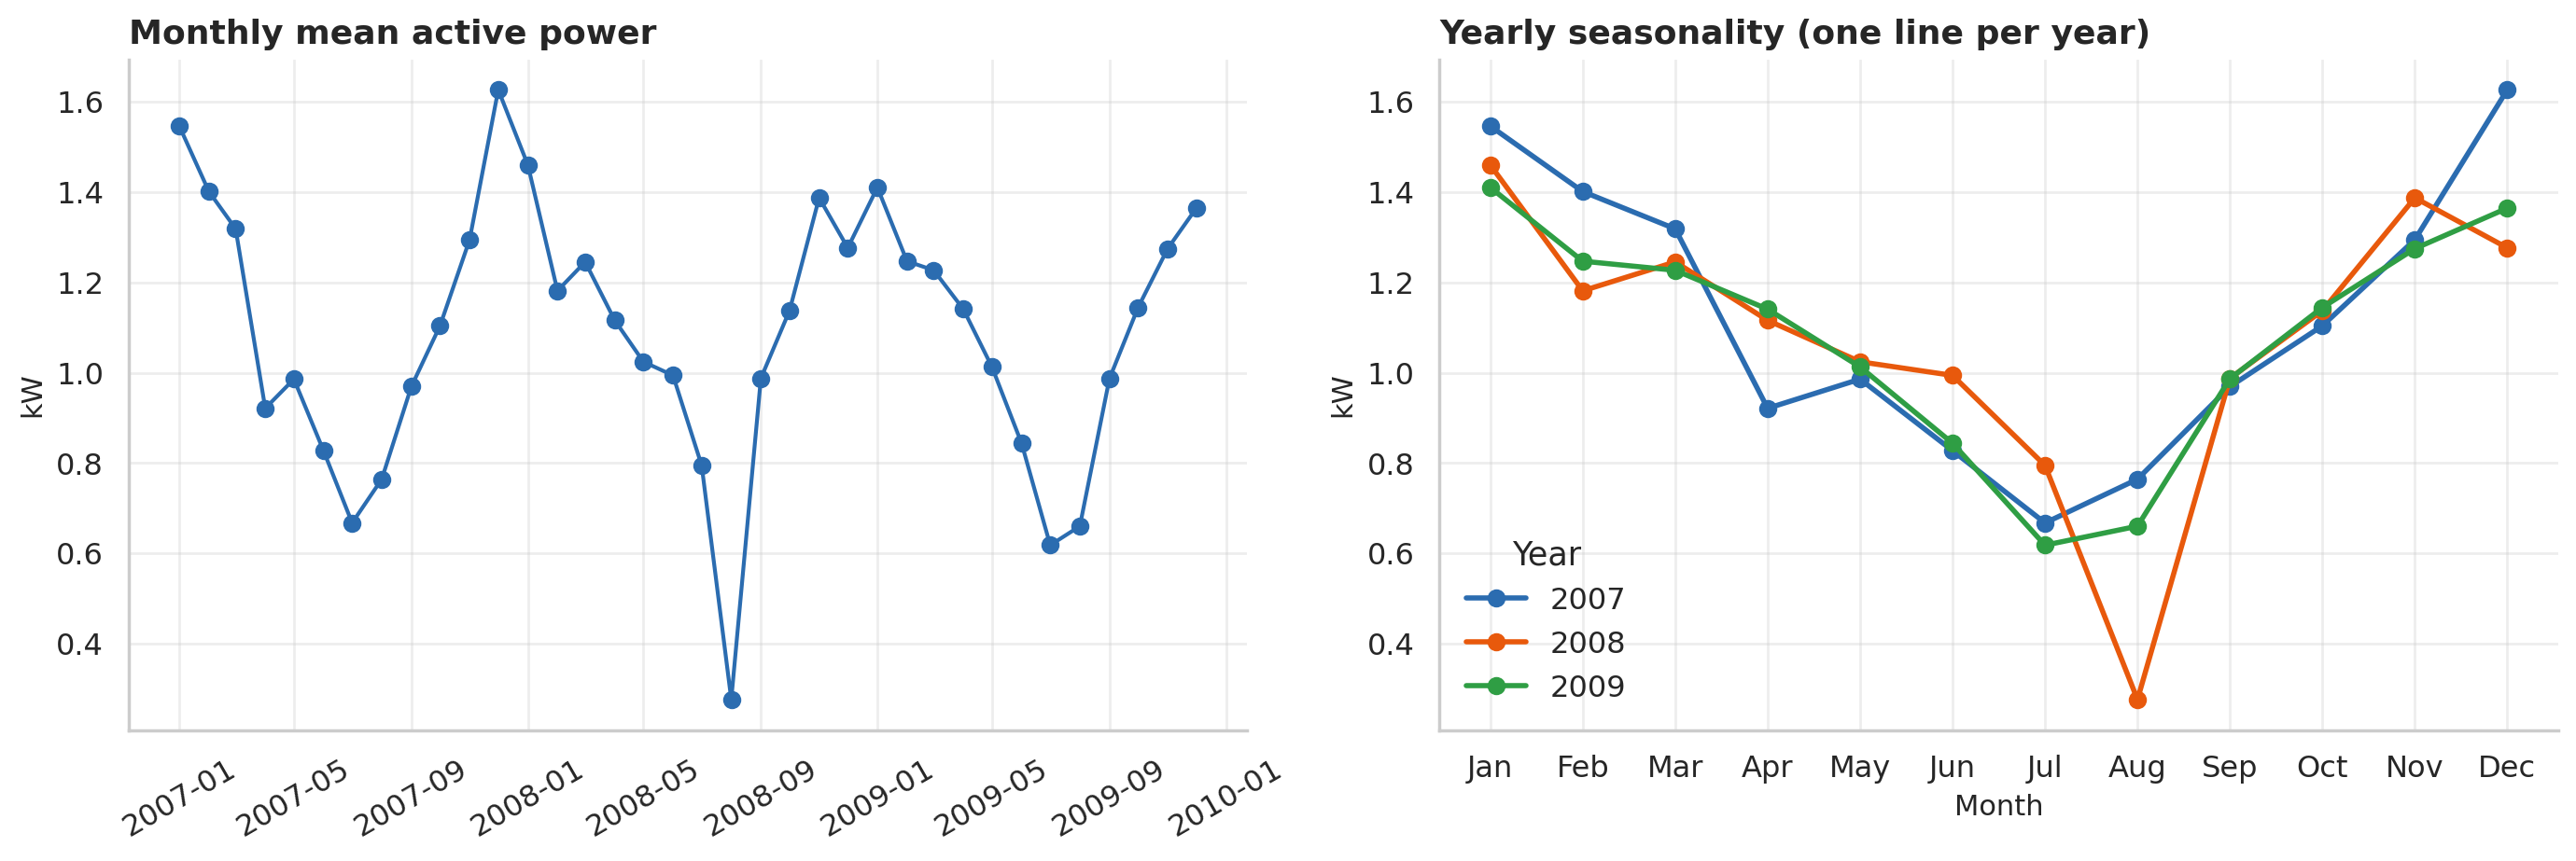

In [24]:
from IPython.display import Image, display

FIG = f'{BASE}/figures'
for name in ['04_daily_profile', '06_heatmap_day_hour', '03_monthly_seasonality']:
    display(Image(f'{FIG}/{name}.png', width=900))

## 4. Models: Baselines vs LSTM

Full experiments in `03_feature_engineering_modeling_renad.ipynb`. Here we rebuild the forecasts on the **same validation windows** (168 hours in → 24 hours out, non-overlapping):

| Model | How it forecasts the next 24 hours |
|---|---|
| Last-value | Repeat the last observed hour |
| Seasonal Naive | Repeat yesterday (lag 24) |
| **Weekly Naive** | Repeat the same hours last week (lag 168) |
| LSTM V1 | LSTM(32) + Dense(24), trained on train windows (loaded from `models/`, no retraining) |

In [25]:
TARGET = 'Global_active_power'
HISTORY, HORIZON = 168, 24
y = df[TARGET].to_numpy()
split_arr = df['split'].to_numpy()

def make_windows(split_name):
    pos = np.where(split_arr == split_name)[0]
    starts = list(range(pos[0], pos[-1] + 2 - HORIZON, HORIZON))
    X = np.array([y[s - HISTORY:s] for s in starts])
    Y = np.array([y[s:s + HORIZON] for s in starts])
    return X, Y, df.index[starts]

X_val, Y_val, val_starts = make_windows('val')
print('Validation windows:', X_val.shape, '->', Y_val.shape)
print('Validation hours:', Y_val.size)

Validation windows: (181, 168) -> (181, 24)
Validation hours: 4344


### 4b. Forecasts on Validation
Each model forecasts the same 181 validation windows. LSTM V1 is loaded from Drive with its train-only scaler.

In [26]:
import joblib
from tensorflow.keras.models import load_model

MODELS = f'{BASE}/models'
lstm = load_model(f'{MODELS}/powercast_lstm.keras', compile=False)
scaler = joblib.load(f'{MODELS}/powercast_scaler.pkl')

def lstm_forecast(X):
    X_scaled = scaler.transform(X.reshape(-1, 1)).reshape(-1, HISTORY, 1)
    pred_scaled = lstm.predict(X_scaled, verbose=0)
    return scaler.inverse_transform(pred_scaled.reshape(-1, 1)).reshape(-1, HORIZON)

def all_forecasts(X):
    return {
        'Last-value':     np.repeat(X[:, -1:], HORIZON, axis=1),
        'Seasonal Naive': X[:, -24:],
        'Weekly Naive':   X[:, :24],
        'LSTM V1':        lstm_forecast(X),
    }

val_preds = all_forecasts(X_val)
for name, P in val_preds.items():
    print(f'{name:15s}', P.shape)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


Last-value      (181, 24)
Seasonal Naive  (181, 24)
Weekly Naive    (181, 24)
LSTM V1         (181, 24)


## 5. Results & Error Analysis

### 5a. Model Comparison on Validation
All models are compared on the same 4,344 validation hours, in kW. **MAE is the main metric.**

In [27]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def smape(a, p):
    a, p = np.ravel(a), np.ravel(p)
    d = np.abs(a) + np.abs(p)
    return 100 * np.mean(np.divide(2 * np.abs(a - p), d, out=np.zeros_like(d), where=d > 0))

def metrics_table(Y, preds):
    rows = []
    for name, P in preds.items():
        rows.append({
            'Model': name,
            'MAE (kW)': mean_absolute_error(Y.ravel(), P.ravel()),
            'RMSE (kW)': np.sqrt(mean_squared_error(Y.ravel(), P.ravel())),
            'sMAPE (%)': smape(Y, P),
            'R²': r2_score(Y.ravel(), P.ravel()),
        })
    return pd.DataFrame(rows).sort_values('MAE (kW)').reset_index(drop=True)

val_results = metrics_table(Y_val, val_preds)
val_results.round(4)

,Model,MAE (kW),RMSE (kW),sMAPE (%),R²
0,Weekly Naive,0.5796,0.8392,49.1379,-0.0666
1,Seasonal Naive,0.6153,0.8822,51.6243,-0.1788
2,LSTM V1,0.7199,0.8622,64.2533,-0.1260
3,Last-value,0.7491,1.0077,67.2551,-0.5381


### 5b. Actual vs Forecast (One Validation Week)
Does the forecast follow the daily cycle and the evening peaks?

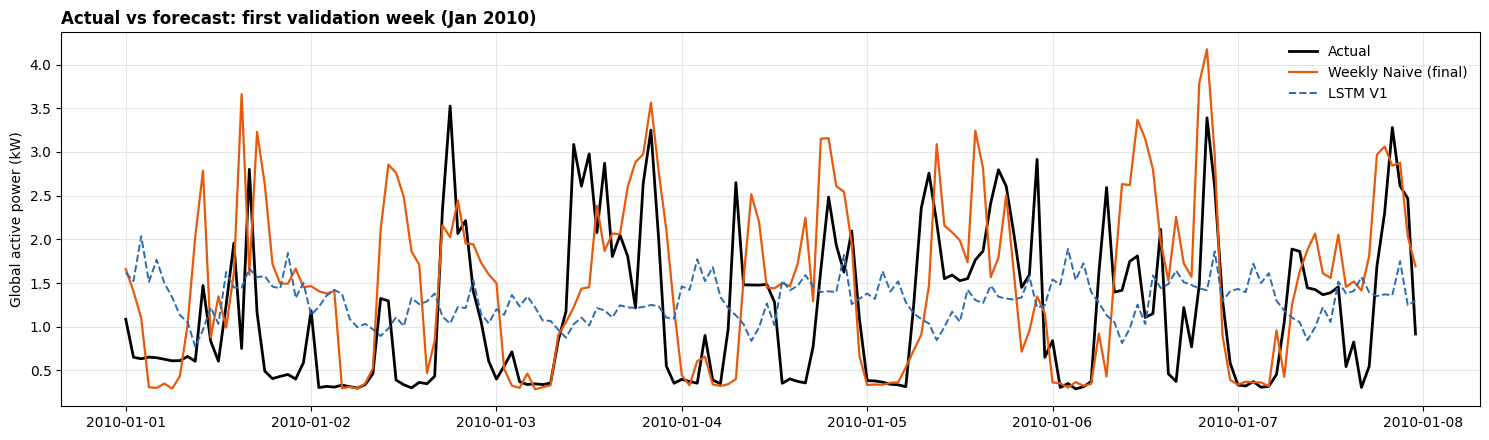

In [28]:
FIG = f'{BASE}/figures'
WEEK = 7  # 7 windows x 24 hours

times = pd.date_range(val_starts[0], periods=WEEK * HORIZON, freq='h')
actual_week = Y_val[:WEEK].ravel()

plt.figure(figsize=(15, 4.5))
plt.plot(times, actual_week, color='black', lw=2, label='Actual')
plt.plot(times, val_preds['Weekly Naive'][:WEEK].ravel(), color='#E8590C', lw=1.6, label='Weekly Naive (final)')
plt.plot(times, val_preds['LSTM V1'][:WEEK].ravel(), color='#2B6CB0', lw=1.4, ls='--', label='LSTM V1')
plt.title('Actual vs forecast: first validation week (Jan 2010)', loc='left', fontweight='bold')
plt.ylabel('Global active power (kW)')
plt.legend(frameon=False)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{FIG}/final_actual_vs_forecast_week.png', dpi=200, bbox_inches='tight')
plt.show()

### 5c. Error Analysis
- **Bias:** does the model forecast too high or too low?
- **High-consumption hours:** how big is the error on the top 25% hours?
- **Peak hour:** does it find the hour of the daily peak?
- **Hour of day:** when is the error largest?

,Model,Bias (kW),MAE high hours (kW),Bias high hours (kW),Peak hour exact (%),Peak hour ±1h (%)
0,Weekly Naive,0.026,0.838,-0.548,13.812,29.834
1,Seasonal Naive,0.003,0.896,-0.652,7.182,26.519
2,LSTM V1,0.078,1.045,-1.045,5.525,14.917


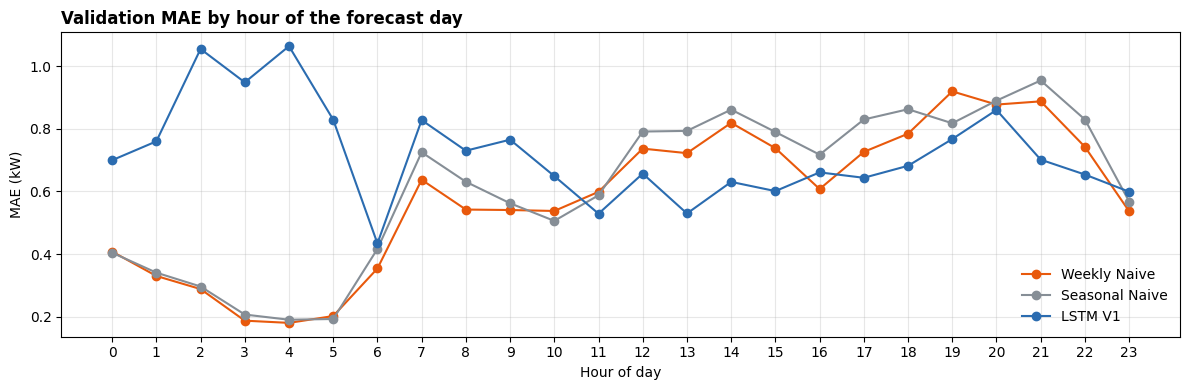

In [29]:
high = Y_val >= np.percentile(Y_val, 75)
rows = []
for name in ['Weekly Naive', 'Seasonal Naive', 'LSTM V1']:
    P = val_preds[name]
    err = P - Y_val
    rows.append({
        'Model': name,
        'Bias (kW)': err.mean(),
        'MAE high hours (kW)': np.abs(err[high]).mean(),
        'Bias high hours (kW)': err[high].mean(),
        'Peak hour exact (%)': 100 * np.mean(P.argmax(1) == Y_val.argmax(1)),
        'Peak hour ±1h (%)': 100 * np.mean(np.abs(P.argmax(1) - Y_val.argmax(1)) <= 1),
    })
display(pd.DataFrame(rows).round(3))

plt.figure(figsize=(12, 4))
for name, c in [('Weekly Naive', '#E8590C'), ('Seasonal Naive', '#868E96'), ('LSTM V1', '#2B6CB0')]:
    plt.plot(range(24), np.abs(val_preds[name] - Y_val).mean(axis=0), marker='o', color=c, label=name)
plt.title('Validation MAE by hour of the forecast day', loc='left', fontweight='bold')
plt.xlabel('Hour of day')
plt.ylabel('MAE (kW)')
plt.xticks(range(24))
plt.legend(frameon=False)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{FIG}/final_error_by_hour.png', dpi=200, bbox_inches='tight')
plt.show()

## 6. Final Test Evaluation
The final model (**Weekly Naive**) was chosen on validation only. Here we evaluate **once** on the untouched test period (Jul–Nov 2010), with the same windows and metrics, and compare with the baselines on the same dates.

In [30]:
X_test, Y_test, test_starts = make_windows('test')
print('Test windows:', X_test.shape, '->', Y_test.shape, '|', Y_test.size, 'hours')
print('From', test_starts[0], 'to', test_starts[-1] + pd.Timedelta(hours=23))

test_preds = all_forecasts(X_test)
test_results = metrics_table(Y_test, test_preds)
test_results.round(4)

Test windows: (148, 168) -> (148, 24) | 3552 hours
From 2010-07-01 00:00:00 to 2010-11-25 23:00:00


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


,Model,MAE (kW),RMSE (kW),sMAPE (%),R²
0,Seasonal Naive,0.4792,0.7341,47.5193,-0.0517
1,Weekly Naive,0.5248,0.7872,53.1791,-0.2095
2,LSTM V1,0.6300,0.7444,68.2038,-0.0815
3,Last-value,0.6380,0.9013,63.3593,-0.5855


## 7. Forecast Demo
One 24-hour forecast with the final model (**Weekly Naive**), using `predict.py` (the same function the Streamlit dashboard uses). Input: the 168 hours **before** the chosen day.

Predicted peak: 07:00 | Actual peak: 07:00
MAE this day: 0.43 kW (average on test: 0.52 kW)
Predicted total: 30.6 kWh


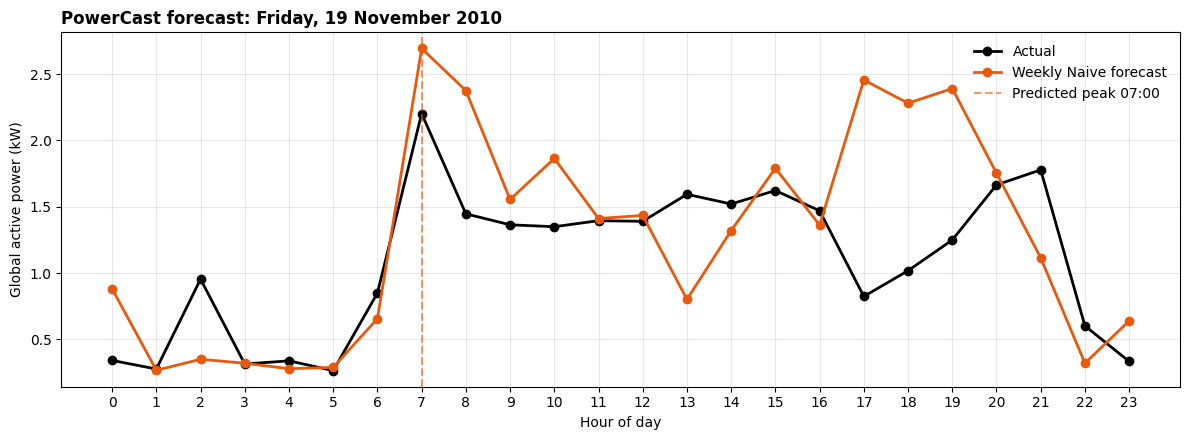

In [31]:
import sys
sys.path.append(BASE)
from predict import predict_next_24h

DEMO_DAY = pd.Timestamp('2010-11-19')
series = df[TARGET]

history = series[DEMO_DAY - pd.Timedelta(hours=168) : DEMO_DAY - pd.Timedelta(hours=1)]
actual = series[DEMO_DAY : DEMO_DAY + pd.Timedelta(hours=23)].to_numpy()
forecast = predict_next_24h(history.to_numpy())

peak_f, peak_a = forecast.argmax(), actual.argmax()
print(f'Predicted peak: {peak_f:02d}:00 | Actual peak: {peak_a:02d}:00')
print(f'MAE this day: {np.abs(actual - forecast).mean():.2f} kW (average on test: 0.52 kW)')
print(f'Predicted total: {forecast.sum():.1f} kWh')

plt.figure(figsize=(12, 4.5))
plt.plot(range(24), actual, color='black', lw=2, marker='o', label='Actual')
plt.plot(range(24), forecast, color='#E8590C', lw=2, marker='o', label='Weekly Naive forecast')
plt.axvline(peak_f, color='#E8590C', ls='--', alpha=0.6, label=f'Predicted peak {peak_f:02d}:00')
plt.title(f'PowerCast forecast: {DEMO_DAY:%A, %d %B %Y}', loc='left', fontweight='bold')
plt.xlabel('Hour of day')
plt.ylabel('Global active power (kW)')
plt.xticks(range(24))
plt.legend(frameon=False)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{FIG}/final_demo_2010-11-19.png', dpi=200, bbox_inches='tight')
plt.show()

## 8. Limitations & Conclusion

### Limitations
- **One household only**: results may not generalize to other homes.
- **No external data**: weather, holidays and household absence are not in the data. Example: **August 2008 drops to 0.28 kW** (vs about 0.7 kW in other years), probably because the family was away. No model can predict that from past consumption alone.
- **Unusual weeks hurt Weekly Naive**: it copies last week, so holidays or travel break the forecast. This likely explains why Seasonal Naive was slightly better on the test period (summer/autumn).
- **Peaks are under-predicted** and the **peak-hour alert is approximate** (exact on 13.8% of validation days, ±1h on 29.8%).
- **LSTM was not tuned far**: small model, non-overlapping windows (1,104 samples), best epoch was the first one.
- **Missing data**: 421 hours (1.2%) were filled; the longest gap was about 5 days.

### Conclusion
- We forecast a household's hourly electricity use for the next 24 hours from the previous 7 days.
- **Weekly Naive** (same hour, last week) was the best model on validation (**MAE 0.580 kW**) and was selected as the final model.
- On the untouched test period it reached **MAE 0.525 kW**, better than the LSTM (0.630) and Last-value (0.638). Seasonal Naive was slightly better on test (0.479); we report this honestly and did not change the model.
- **Main learning:** always compare with a simple baseline. A more complex model is not automatically better.
- **Next steps:** add calendar and holiday features, train the LSTM on overlapping windows, and add weather data.

---

## ⚡ PowerCast in one line
**A simple "same hour, last week" forecast predicts this household's next 24 hours with an average error of about 0.5 kW, and it beat the LSTM.**

| | Validation | Test |
|---|---|---|
| Final model | Weekly Naive | Weekly Naive |
| MAE (kW) | 0.580 | 0.525 |

**Files:** `data/hourly_clean.csv` · `models/` · `figures/` · `predict.py` · `app.py` (Streamlit dashboard)

**Team:** Rana Aljumayi · Salwa · Renad · Raneem | Le Wagon Data Science #2344

*Thank you!* 🙏